# Fine-Tuning a Small Language Model for Roman Urdu–English Complaint Triage

**Base model:** `Qwen/Qwen2.5-1.5B-Instruct` · **Method:** QLoRA (Hugging Face PEFT) · **Task:** label each customer
message with `category`, `urgency` and `sentiment` (JSON output).

Steps: data split → TF-IDF baseline → **base model (zero-shot)** → **QLoRA fine-tuning** → **fine-tuned model** on the
same held-out test set → comparison, charts, error analysis → Gradio demo.


## 1. Mount Google Drive and open the project folder

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/NLP Project"
!ls

Mounted at /content/drive
/content/drive/MyDrive/NLP Project
app.py	data  notebooks  README.md  requirements.txt  results  src


## 2. Install libraries and check the GPU

In [2]:
!pip install -q -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 3. Train / validation / test split (by paraphrase group, no leakage)

In [3]:
!python src/prepare_data.py

train rows= 3212 groups=123 languages={'roman_urdu': 1095, 'en': 1077, 'mixed': 1040}
val   rows=  424 groups= 18 languages={'en': 167, 'roman_urdu': 167, 'mixed': 90}  MISSING {'category': ['general_inquiry']}
test  rows=  992 groups= 36 languages={'roman_urdu': 440, 'en': 280, 'mixed': 272}
Wrote /content/drive/MyDrive/NLP Project/data/splits/{train,val,test}.jsonl and results/dataset_stats.json


## 4. Classic baseline: TF-IDF + Logistic Regression

In [4]:
!python src/tfidf_baseline.py

{
  "category": {
    "macro_f1": 0.7378,
    "accuracy": 0.7681,
    "invalid_rate": 0.0,
    "macro_f1_en": 0.8039,
    "accuracy_en": 0.8464,
    "macro_f1_roman_urdu": 0.7927,
    "accuracy_roman_urdu": 0.8114,
    "macro_f1_mixed": 0.6141,
    "accuracy_mixed": 0.6176
  },
  "urgency": {
    "macro_f1": 0.7649,
    "accuracy": 0.7671,
    "invalid_rate": 0.0,
    "macro_f1_en": 0.8461,
    "accuracy_en": 0.8071,
    "macro_f1_roman_urdu": 0.8306,
    "accuracy_roman_urdu": 0.8318,
    "macro_f1_mixed": 0.6398,
    "accuracy_mixed": 0.6213
  },
  "sentiment": {
    "macro_f1": 0.8361,
    "accuracy": 0.8669,
    "invalid_rate": 0.0,
    "macro_f1_en": 0.8801,
    "accuracy_en": 0.9286,
    "macro_f1_roman_urdu": 0.93,
    "accuracy_roman_urdu": 0.9341,
    "macro_f1_mixed": 0.6961,
    "accuracy_mixed": 0.6949
  },
  "all_three_correct": 0.5726
}


## 5. Base model, zero-shot (no fine-tuning) on the test set  ·  ~10 min on a T4

In [5]:
!python src/eval_slm.py --name base

config.json: 100% 660/660 [00:00<00:00, 2.26MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 35.9kB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 59.4MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 87.8MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 111MB/s]

model.safetensors: downloading bytes:   0% 0.00/3.09G [00:00<?, ?B/s]
model.safetensors: downloading bytes:   2% 76.5M/3.09G [00:01<00:29, 102MB/s, 5.32MB/s  ] 
model.safetensors: downloading bytes:   5% 155M/3.09G [00:01<00:17, 165MB/s, 12.3MB/s  ]
model.safetensors: downloading bytes:   6% 185M/3.09G [00:01<00:14, 195MB/s, 14.5MB/s  ]
model.safetensors: reconstructing file:   3% 81.8M/3.09G [00:01<00:35, 84.3MB/s,  640kB/s  ]
model.safetensors: downloading bytes:   7% 211M/3.09G [00:02<00:17, 167MB/s, 18.2MB/s  ]
model.safetensors: downloading bytes:   8% 237M/3.09G [00:02<00:18, 151MB/s, 20.2MB/s  ]
model.safetensors: downloading bytes:  10% 313M/3.09G [00:02<00:13, 206MB/s, 25.7MB/s  ]
model.safetensors: recon

## 6. QLoRA fine-tuning  ·  ~40–60 min on a T4
The adapter is saved to `outputs/complaint-lora` (on Drive, so it survives a disconnect).

In [6]:
!python src/train_qlora.py

train 3212 | val 424 | tokens per example: max 397, mean 369 | answer tokens: 23
Loading weights: 100% 338/338 [00:01<00:00, 287.75it/s]
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
  0% 2/402 [01:07<3:45:37, 33.84s/it][W1121 11:58:22.386612398 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1902116864 bytes (free: 1900544, total: 15637086208).
{'loss': '0.1715', 'grad_norm': '0.4543', 'learning_rate': '9e-05', 'epoch': '0.04975'}
  3% 14/402 [07:49<3:36:47, 33.53s/it][W1121 12:04:48.588925621 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1920991232 bytes (free: 580714496, total: 15637086208).
{'loss': '0.08279', 'grad_norm': '0.2619', 'learning_rate': '0.00019', 'epoch': '0.0995'}
{'loss': '0.04014', 'grad_norm': '0.3872', 'learning_rate': '0.0001997', 'epoch': '0.1493'}
{'loss': '0.04444', 'grad_norm': '0.3721', 'learning_rate': '0.0001988',

## 7. Fine-tuned model on the same test set

In [7]:
!python src/eval_slm.py --name finetuned --adapter

Loading weights: 100% 338/338 [00:01<00:00, 275.58it/s]
{
  "category": {
    "macro_f1": 0.9122,
    "accuracy": 0.9173,
    "invalid_rate": 0.0,
    "macro_f1_en": 0.9911,
    "accuracy_en": 0.9929,
    "macro_f1_roman_urdu": 0.8137,
    "accuracy_roman_urdu": 0.8455,
    "macro_f1_mixed": 0.9603,
    "accuracy_mixed": 0.9559
  },
  "urgency": {
    "macro_f1": 0.8672,
    "accuracy": 0.872,
    "invalid_rate": 0.0,
    "macro_f1_en": 0.8871,
    "accuracy_en": 0.875,
    "macro_f1_roman_urdu": 0.8623,
    "accuracy_roman_urdu": 0.8682,
    "macro_f1_mixed": 0.841,
    "accuracy_mixed": 0.875
  },
  "sentiment": {
    "macro_f1": 0.9261,
    "accuracy": 0.9133,
    "invalid_rate": 0.0,
    "macro_f1_en": 0.9134,
    "accuracy_en": 0.9464,
    "macro_f1_roman_urdu": 0.906,
    "accuracy_roman_urdu": 0.9068,
    "macro_f1_mixed": 0.9068,
    "accuracy_mixed": 0.8897
  },
  "all_three_correct": 0.7732,
  "json_valid_rate": 1.0,
  "model": "Qwen/Qwen2.5-1.5B-Instruct + LoRA (/content/dri

## 8. Comparison table, charts and error analysis

# Results on the held-out test set

### category

| Model | macro_f1 | accuracy | macro_f1_en | macro_f1_roman_urdu | macro_f1_mixed | invalid_rate |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.738 | 0.768 | 0.804 | 0.793 | 0.614 | 0.000 |
| Base SLM (zero-shot) | 0.623 | 0.681 | 0.740 | 0.488 | 0.657 | 0.005 |
| Fine-tuned SLM (QLoRA) | 0.912 | 0.917 | 0.991 | 0.814 | 0.960 | 0.000 |

### urgency

| Model | macro_f1 | accuracy | macro_f1_en | macro_f1_roman_urdu | macro_f1_mixed | invalid_rate |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.765 | 0.767 | 0.846 | 0.831 | 0.640 | 0.000 |
| Base SLM (zero-shot) | 0.408 | 0.535 | 0.464 | 0.350 | 0.362 | 0.005 |
| Fine-tuned SLM (QLoRA) | 0.867 | 0.872 | 0.887 | 0.862 | 0.841 | 0.000 |

### sentiment

| Model | macro_f1 | accuracy | macro_f1_en | macro_f1_roman_urdu | macro_f1_mixed | invalid_rate |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.836 | 0.867 | 0.880 | 0.930 | 0.696 | 0.000 |
| Base SLM (zero-shot) | 0.690

# Results on the held-out test set

### category

| Model | macro_f1 | accuracy | macro_f1_en | macro_f1_roman_urdu | macro_f1_mixed | invalid_rate |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.738 | 0.768 | 0.804 | 0.793 | 0.614 | 0.000 |
| Base SLM (zero-shot) | 0.623 | 0.681 | 0.740 | 0.488 | 0.657 | 0.005 |
| Fine-tuned SLM (QLoRA) | 0.912 | 0.917 | 0.991 | 0.814 | 0.960 | 0.000 |

### urgency

| Model | macro_f1 | accuracy | macro_f1_en | macro_f1_roman_urdu | macro_f1_mixed | invalid_rate |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.765 | 0.767 | 0.846 | 0.831 | 0.640 | 0.000 |
| Base SLM (zero-shot) | 0.408 | 0.535 | 0.464 | 0.350 | 0.362 | 0.005 |
| Fine-tuned SLM (QLoRA) | 0.867 | 0.872 | 0.887 | 0.862 | 0.841 | 0.000 |

### sentiment

| Model | macro_f1 | accuracy | macro_f1_en | macro_f1_roman_urdu | macro_f1_mixed | invalid_rate |
|---|---|---|---|---|---|---|
| TF-IDF + LogReg | 0.836 | 0.867 | 0.880 | 0.930 | 0.696 | 0.000 |
| Base SLM (zero-shot) | 0.690 | 0.769 | 0.716 | 0.655 | 0.644 | 0.005 |
| Fine-tuned SLM (QLoRA) | 0.926 | 0.913 | 0.913 | 0.906 | 0.907 | 0.000 |

### Overall

| Model | all three labels correct | valid JSON | seconds / example |
|---|---|---|---|
| TF-IDF + LogReg | 0.573 | 1.000 | - |
| Base SLM (zero-shot) | 0.339 | 0.995 | 0.807 |
| Fine-tuned SLM (QLoRA) | 0.773 | 1.000 | 0.772 |


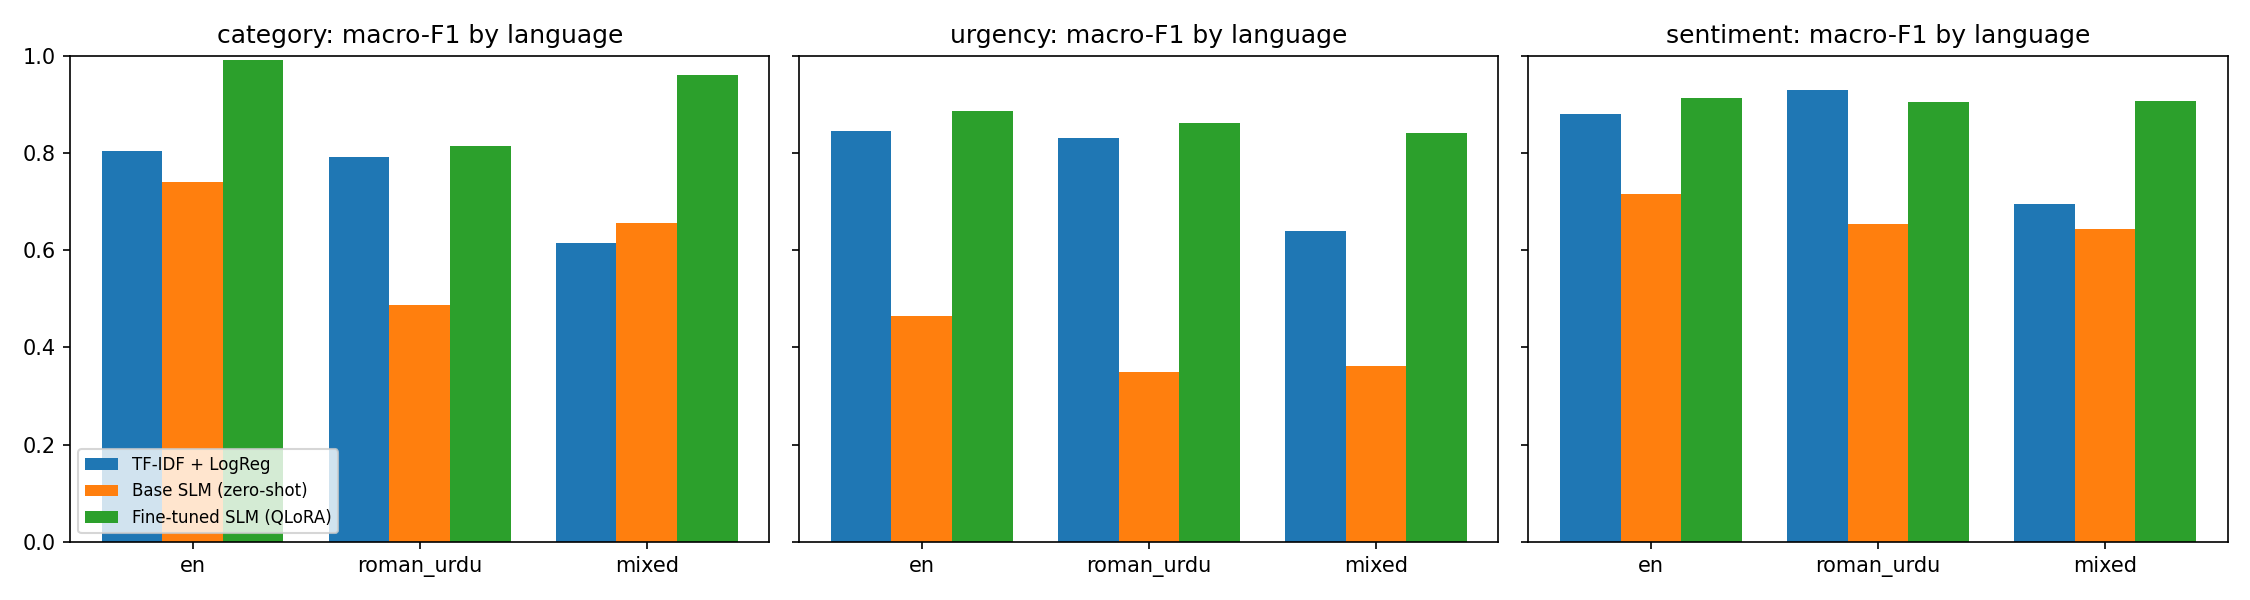

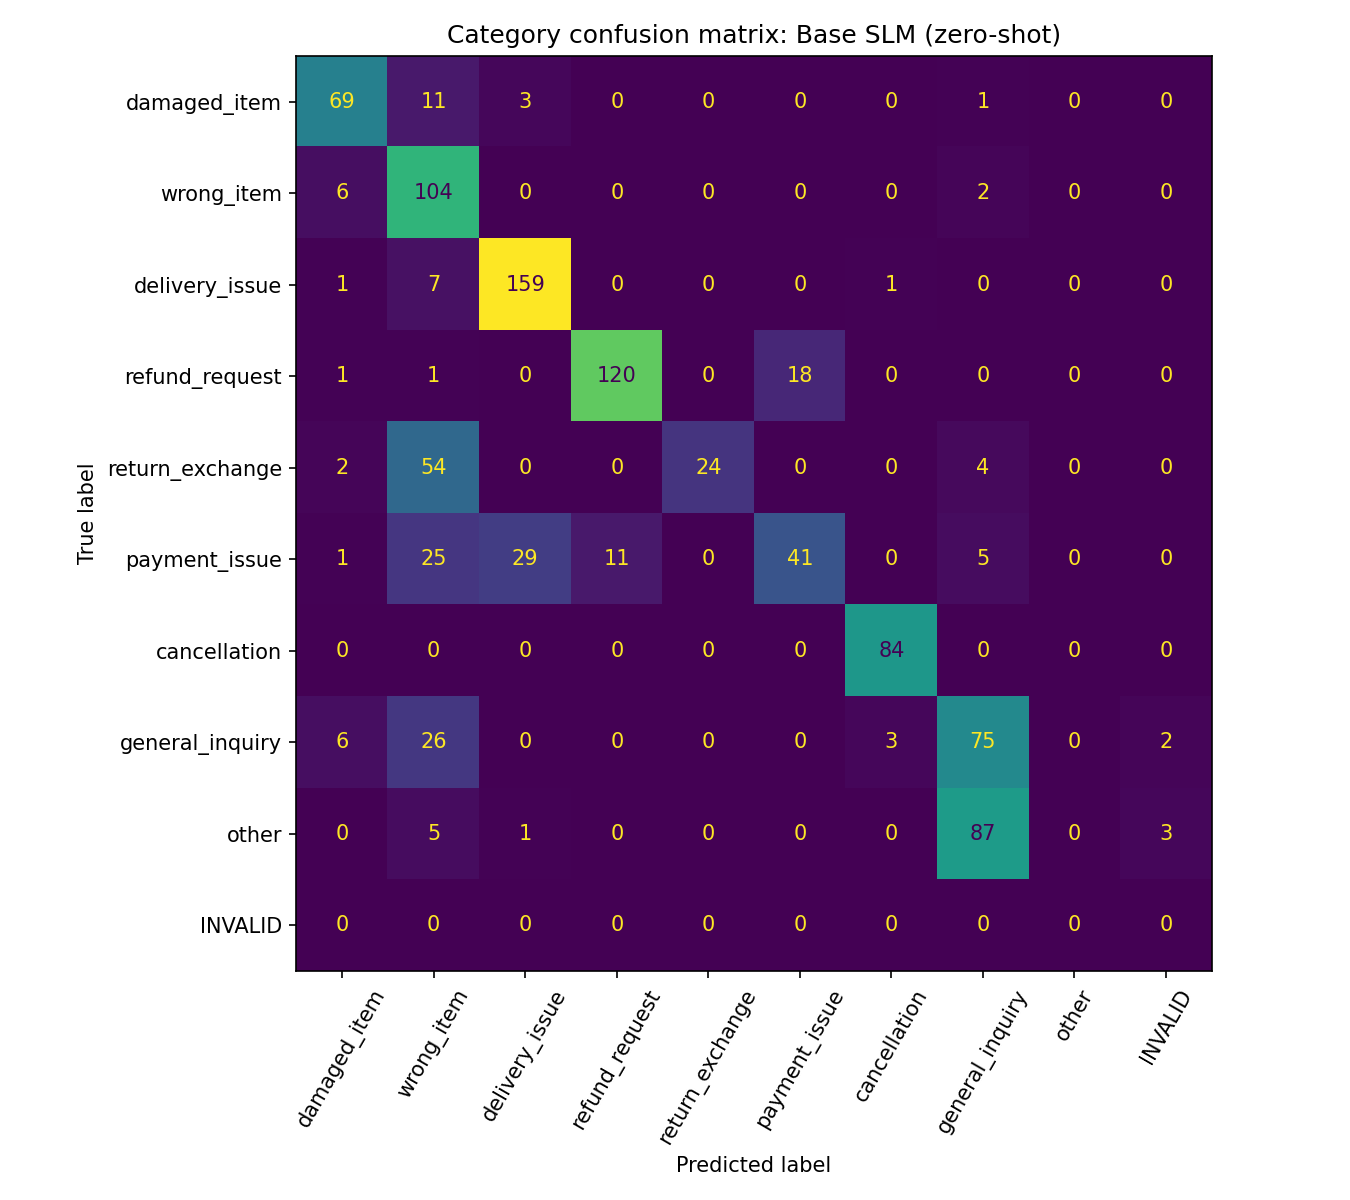

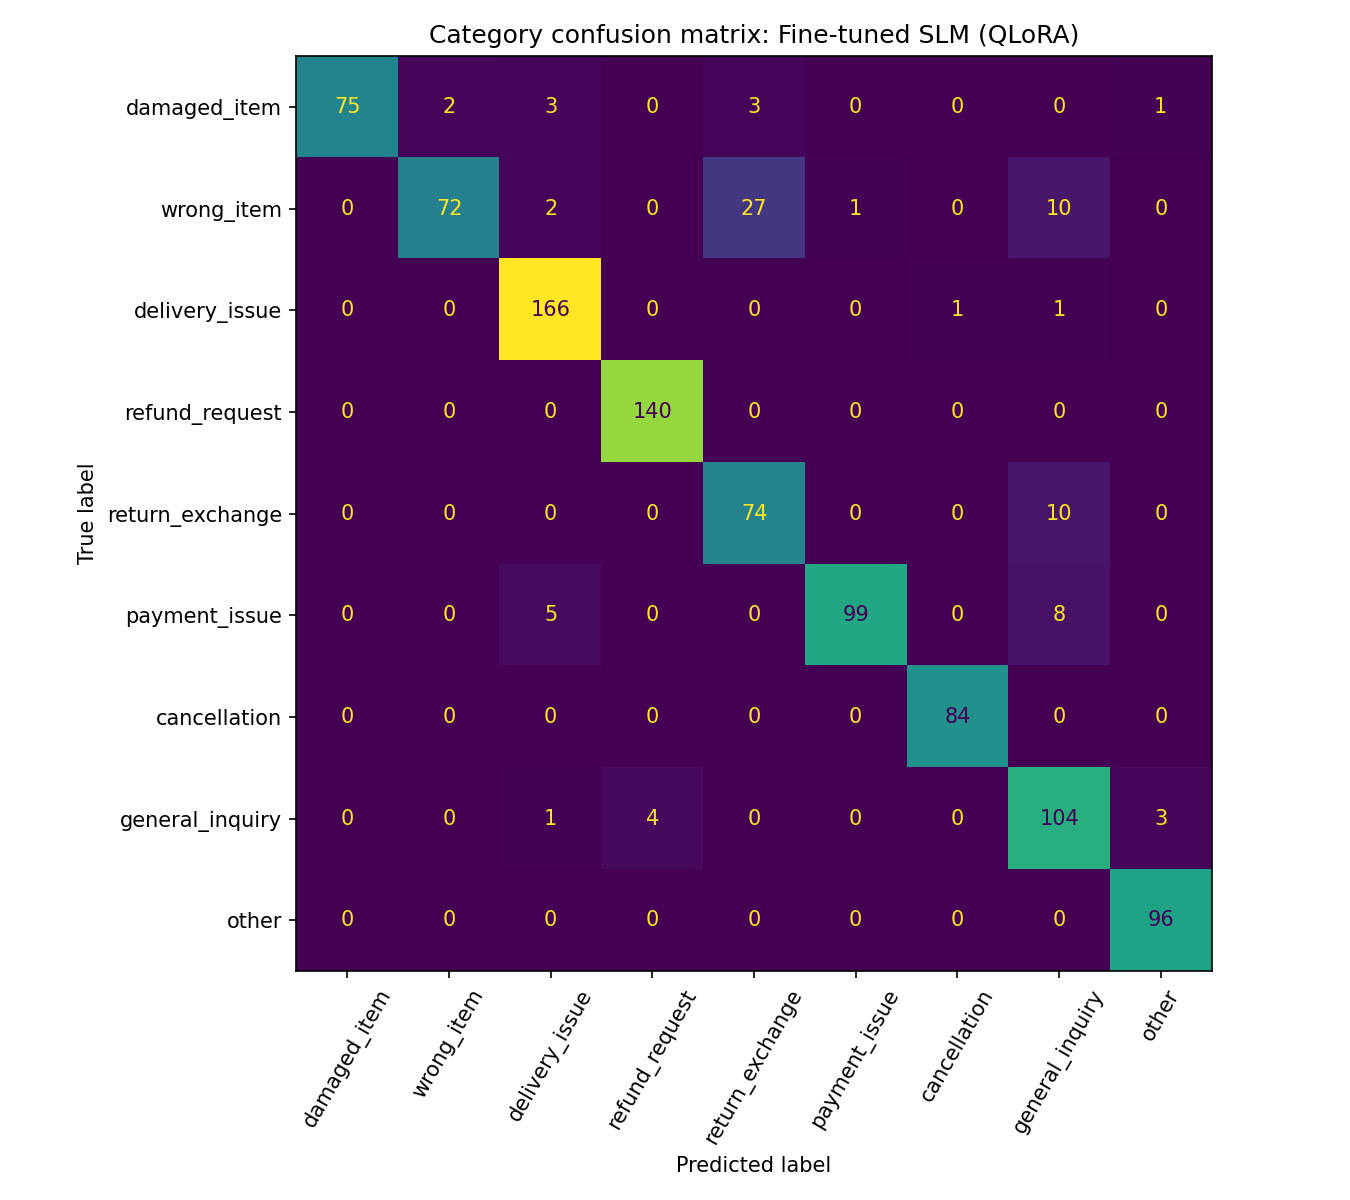

In [8]:
!python src/compare.py
from IPython.display import Image, Markdown, display
display(Markdown(open('results/comparison.md', encoding='utf-8').read()))
for f in ['f1_by_language.png', 'confusion_category_base.png', 'confusion_category_finetuned.png']:
    display(Image(f'results/{f}'))

In [9]:
import pandas as pd
print('Fixed by fine-tuning (base wrong, fine-tuned right):')
display(pd.read_csv('results/fixed_by_finetuning.csv').head(10))
print('Still wrong after fine-tuning:')
display(pd.read_csv('results/errors_finetuned.csv')[['text', 'language', 'category', 'pred_category', 'urgency', 'pred_urgency', 'sentiment', 'pred_sentiment']].head(15))

Fixed by fine-tuning (base wrong, fine-tuned right):


,text,language,category,urgency,sentiment,pred_category,pred_urgency,pred_sentiment
0,bedsheet ki quality amazing hai thank you so m...,mixed,other,low,positive,general_inquiry,high,positive
1,"Mere account se do dafa pese kat gaye, check k...",roman_urdu,payment_issue,high,negative,wrong_item,high,negative
2,What are your shop timings Worst service ever ...,en,general_inquiry,high,negative,cancellation,high,negative
3,"Excuse me, Why is my order delayed. Kindly rep...",en,delivery_issue,medium,negative,delivery_issue,high,negative
4,AOA itni der kyun lag rahi hai order mein. jal...,roman_urdu,delivery_issue,medium,negative,delivery_issue,high,negative
5,sale kab start ho rahi ha. very bad service ha...,mixed,general_inquiry,high,negative,wrong_item,high,negative
6,"Hello bhai shoes return karna hai, rider kab a...",mixed,return_exchange,low,neutral,return_exchange,high,neutral
7,Itni der kyun lag rahi ha order mein. Order nu...,roman_urdu,delivery_issue,medium,negative,delivery_issue,high,negative
8,"Nice quality he, love it 😊",mixed,other,low,positive,general_inquiry,low,positive
9,"Nice quality hai, love it ❤️",mixed,other,low,positive,INVALID,INVALID,INVALID


Still wrong after fine-tuning:


,text,language,category,pred_category,urgency,pred_urgency,sentiment,pred_sentiment
0,Where is my order it was supposed to arrive th...,en,delivery_issue,delivery_issue,medium,high,negative,negative
1,Bhai mujhay ye watch waapis karna hy. aakhri d...,roman_urdu,return_exchange,general_inquiry,high,high,negative,negative
2,"Hi, Where is my order, it was supposed to arri...",en,delivery_issue,delivery_issue,medium,high,negative,negative
3,"Assalam o alaikum, bas bata dein refund proces...",roman_urdu,refund_request,refund_request,low,medium,neutral,negative
4,"Hi, totally different product aya he, refund c...",mixed,wrong_item,wrong_item,medium,high,negative,negative
5,"corier wala bol rha hai address nahi mila, kb ...",mixed,delivery_issue,delivery_issue,medium,medium,neutral,negative
6,"sir bas bata den refund process hua ya nahi, m...",roman_urdu,refund_request,refund_request,low,medium,neutral,neutral
7,"AOA, totally different product aayaa hai. Plea...",mixed,wrong_item,wrong_item,medium,high,negative,negative
8,"Sir do shoes mangwaye thay, ek hi aaya 😠",roman_urdu,wrong_item,return_exchange,high,high,negative,negative
9,"hello bhai cod ka option show nahi ho raha, am...",mixed,payment_issue,general_inquiry,low,low,neutral,neutral


## 9. Training curve

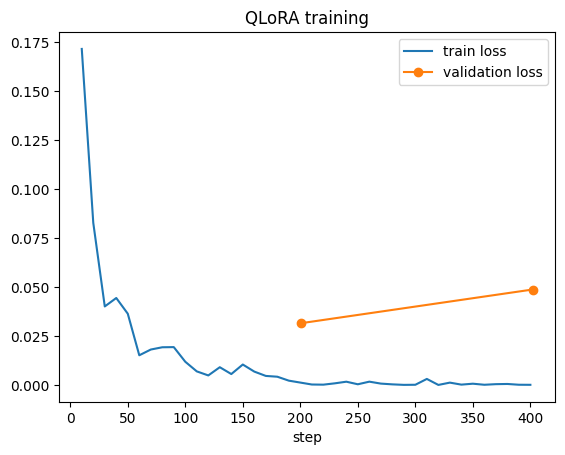

In [10]:
import json, matplotlib.pyplot as plt
log = json.load(open('results/train_log.json'))['history']
tr = [(h['step'], h['loss']) for h in log if 'loss' in h]
ev = [(h['step'], h['eval_loss']) for h in log if 'eval_loss' in h]
plt.plot(*zip(*tr), label='train loss'); plt.plot(*zip(*ev), 'o-', label='validation loss')
plt.xlabel('step'); plt.legend(); plt.title('QLoRA training'); plt.savefig('results/training_curve.png', dpi=150); plt.show()

## 10. Gradio demo (base vs fine-tuned, side by side)
Open the public link that appears below.

In [ ]:
!python app.py --share

Training the TF-IDF baseline...
Loading Qwen/Qwen2.5-1.5B-Instruct + LoRA adapter from /content/drive/MyDrive/NLP Project/outputs/complaint-lora
Loading weights: 100% 338/338 [00:01<00:00, 272.40it/s]
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://fcd4f15a1ea9cb6a93.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
